# 02 · Run modes and the memory guard

A run produces `T × N × N` complex64 frames (8 bytes per pixel): 200 ticks at 256² is 100 MiB, but 10 000
ticks at 1024² is 78 GiB. OPAL therefore has four ways of running the same channel (README §4):

| Mode | Where the frames go | GPU memory | Use it when |
|---|---|---|---|
| `device` | kept on the GPU, copied out at the end | grows with T | the whole output fits on the GPU (fastest) |
| `host` | streamed to host RAM or a memory-mapped `frames.npy` | flat | the output fits on disk / in RAM but not on the GPU |
| `chunked` | written to disk in `frames_XXXXX.npy` pieces | bounded by the chunk | very long runs |
| `no_save` | only the final field is kept | flat | benchmarks, or when only the final state matters |

All four evolve the *same* channel: with the same seed they produce bit-identical frames. `mode="auto"`
(the default) lets the memory guard measure the simulator's baseline memory and choose.

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


In [2]:
sim = opal.GpuSimulator(opal.load_config("configs/quickstart_256.json", overrides={"steps": 100}))

## 1. What would the guard do? (dry run)

The guard measures the GPU memory of one tick, predicts the peak of every mode for the requested run, and picks
the fastest mode that fits. Nothing is simulated here. CLI: `opal plan -c configs/quickstart_256.json --steps 200000`.

In [3]:
from opal import memory

baseline = memory.measure_baseline_peak_bytes(sim)
print(f"baseline (simulator + one tick): {baseline / 2**30:.2f} GiB\n")
for steps in (100, 5_000, 200_000):
    est = memory.estimate_memory(steps, sim.nx_size, baseline)
    mode, chunk, reason = memory.select_mode("auto", est, has_output_dir=True)
    print(f"{steps:>7,d} ticks ({est['full_output_bytes'] / 2**30:6.2f} GiB of frames) -> {mode:8s} {reason}")

print("\nfull plan for 200,000 ticks:")
for line in memory.format_plan(est, "auto", mode, chunk):
    print(line)

baseline (simulator + one tick): 0.04 GiB

    100 ticks (  0.05 GiB of frames) -> device   auto: full output fits on the GPU -> device
  5,000 ticks (  2.44 GiB of frames) -> device   auto: full output fits on the GPU -> device
200,000 ticks ( 97.66 GiB of frames) -> host     auto: streaming frames to host keeps GPU memory flat -> host

full plan for 200,000 ticks:
memory plan: N=256 steps=200000 requested=auto -> host
  frame 0.5 MiB | output 97.66 GiB | baseline 0.04 GiB | margin 3.20 GiB | GPU 15.99 GiB | RAM avail 36.48 GiB
  predicted GPU peak: device 198.55 GiB (too big) | host 3.24 GiB | chunked 3.34 GiB (chunk<=100)


## 2. Run the same 100 ticks in every mode

`chunk_size=32` makes the chunked run write four files. `log=None` silences the per-run log lines.

In [4]:
runs = {}
for mode in ("device", "host", "chunked", "no_save"):
    res = runs[mode] = opal.run(sim, mode=mode, out_dir=f"runs/modes/{mode}", chunk_size=32, log=None)
    files = sorted(p.name for p in Path(f"runs/modes/{mode}").iterdir())
    print(f"{mode:8s} {res.steps_per_second:7.1f} ticks/s, peak GPU "
          f"{res.manifest['gpu']['run_peak_bytes'] / 2**20:6.1f} MiB | {', '.join(files)}")

device       6.3 ticks/s, peak GPU  124.5 MiB | frames.npy, manifest.json


host         6.0 ticks/s, peak GPU   37.3 MiB | frames.npy, manifest.json


chunked      6.3 ticks/s, peak GPU   60.0 MiB | frames_chunk_000.npy, frames_chunk_001.npy, frames_chunk_002.npy, frames_chunk_003.npy, frames_chunk_manifest.json, manifest.json


no_save      6.2 ticks/s, peak GPU   37.5 MiB | final_frame.npy, manifest.json


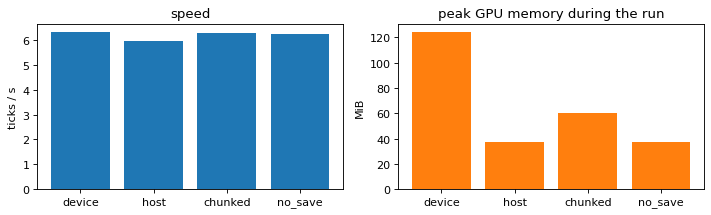

In [5]:
names = list(runs)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].bar(names, [runs[m].steps_per_second for m in names], color="tab:blue")
axes[0].set(ylabel="ticks / s", title="speed")
axes[1].bar(names, [runs[m].manifest["gpu"]["run_peak_bytes"] / 2**20 for m in names], color="tab:orange")
axes[1].set(ylabel="MiB", title="peak GPU memory during the run")
plt.tight_layout()
plt.show()

At 100 ticks of 256² the output is only 50 MiB, so the differences are small; the `device` peak grows with the
number of ticks while the others stay flat, which is what lets `host` and `chunked` run for as long as there
is disk space.

## 3. Same channel, bit for bit

In [6]:
ref = opal.load_frames("runs/modes/device")
for mode in ("host", "chunked"):
    print(f"{mode:8s} == device:     {np.array_equal(opal.load_frames(f'runs/modes/{mode}'), ref)}")
print(f"no_save  == device[-1]: {np.array_equal(opal.load_frames('runs/modes/no_save')[0], ref[-1])}")

host     == device:     True


chunked  == device:     True
no_save  == device[-1]: True


## 4. Reading large outputs lazily

`open_frames` returns a `FrameSeries`: it indexes like an array over all chunk files but reads only the frames
you ask for, so a 100 GiB run can be inspected with a few MiB of RAM. `iter_frames` streams them one by one.

In [7]:
fs = opal.open_frames("runs/modes/chunked")
print(fs)
print("kind", fs.kind, "| shape", fs.shape, "| dtype", fs.dtype, "| ticks", fs.steps[0], "...", fs.steps[-1])
print("fs[30:34] ->", fs[30:34].shape, "(ticks 30-33 span the first two chunk files; only those 4 frames are read)")

n = sum(1 for _ in opal.iter_frames("runs/modes/chunked", stride=10))
print(f"iter_frames(stride=10) streamed {n} frames")

FrameSeries(chunked, 100 x 256 x 256 complex64, 0.05 GiB on disk from runs\modes\chunked)
kind chunked | shape (100, 256, 256) | dtype complex64 | ticks 0 ... 99
fs[30:34] -> (4, 256, 256) (ticks 30-33 span the first two chunk files; only those 4 frames are read)
iter_frames(stride=10) streamed 10 frames


## CLI equivalents

```bash
opal plan -c configs/quickstart_256.json --steps 200000          # dry run: which mode and why
opal run  -c configs/quickstart_256.json --mode chunked --chunk-size 32 -o runs/modes/chunked
opal run  -c configs/quickstart_256.json --no-save                # benchmark
```